In [20]:
from langgraph.graph import StateGraph,START,END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from typing import TypedDict,Annotated
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import HumanMessage,AIMessage,SystemMessage,BaseMessage
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver

In [21]:
load_dotenv()

True

In [22]:
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [23]:
llm=ChatOpenAI(model='gpt-4o')

In [24]:
def chat_node(state:ChatState):
    messages=state['messages']
    response=llm.invoke(messages)
    return {'messages':response}

In [25]:
graph=StateGraph(ChatState)


In [26]:
# Add Node

graph.add_node('chat_node',chat_node)

# Add Edges
graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

In [27]:
checkpointer=MemorySaver()

In [28]:
chatbot=graph.compile(checkpointer=checkpointer)

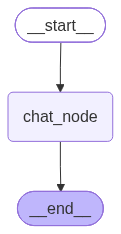

In [29]:
chatbot

In [11]:
# initial_state={'messages':[SystemMessage(content='you are a helpful assistent.'),
#                            HumanMessage(content='which planet is farthest from earch in our solar system')]}

In [14]:
initial_state={'messages':[SystemMessage(content='you are a helpful assistent.')]}

In [13]:
chatbot.invoke(initial_state)

{'messages': [SystemMessage(content='you are a helpful assistent.', additional_kwargs={}, response_metadata={}, id='a646d0a0-58a6-4a02-b8e4-d322330400eb'),
  AIMessage(content="Got it! I'm here to help you with any questions or information you need. What can I assist you with today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 24, 'prompt_tokens': 14, 'total_tokens': 38, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_6c72fd0c80', 'id': 'chatcmpl-EeJ7hn9UbEy9HN84iGJrEv7DIP3A6', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1878a-147f-72d7-b628-1dfa278f6ac7-0', tool

In [ ]:
# while True:
#     user_query=input('Chat Here.....')
#     initial_state['messages'].append(HumanMessage(content=user_query))
#     if user_query.lower() in ['bye','exit','quit']:
#         break
#     initial_state = chatbot.invoke(initial_state)
#     print(initial_state)
#     print("\n =============================================== \n")


{'messages': [SystemMessage(content='you are a helpful assistent.', additional_kwargs={}, response_metadata={}, id='2727d1fa-1d8c-45b1-be0f-6549ff9c29cf'), HumanMessage(content='hello', additional_kwargs={}, response_metadata={}, id='551e0d48-7bc5-4582-a7d7-e52fad2aca80'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 19, 'total_tokens': 28, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_e85bcce457', 'id': 'chatcmpl-EeJ7tiOKWKDSGUcHSJM2n71wto6Yz', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01

In [30]:
thread_id=1
while True:
    user_query=input('Chat Here.....')
    # initial_state['messages'].append(HumanMessage(content=user_query))
    if user_query.lower() in ['bye','exit','quit']:
        break
    config={'configurable':{'thread_id':thread_id}}
    response = chatbot.invoke({'messages':[HumanMessage(content=user_query)]},config=config)
    print(response)
    print("\n =============================================== \n")


{'messages': [HumanMessage(content='hello', additional_kwargs={}, response_metadata={}, id='28852ad6-cc39-466e-aef2-a06f94fc2815'), AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_773fccf863', 'id': 'chatcmpl-EeJI6nw14PqCIi5cKKBijUp575rOh', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a18793-efe4-71ab-8912-fdc7b6037938-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_toke